<a href="https://colab.research.google.com/github/u1463836/IS-Project/blob/main/fixtrain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install scikit-learn

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving y_test.csv to y_test.csv
Saving y_train.csv to y_train.csv
Saving X_test.csv to X_test.csv
Saving X_train.csv to X_train.csv


In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv").squeeze()
y_test = pd.read_csv("y_test.csv").squeeze()

model = LogisticRegression(random_state=42, max_iter=1000, class_weight="balanced")
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Logistic Regression Results")
print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1 Score:  {f1:.2%}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

coef_df = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": model.coef_[0]
}).sort_values("coefficient", key=abs, ascending=False)

print("\nTop 10 most influential features:")
print(coef_df.head(10).to_string(index=False))

Logistic Regression Results
Accuracy:  72.50%
Precision: 80.77%
Recall:    77.78%
F1 Score:  79.25%

Confusion Matrix:
[[ 8  5]
 [ 6 21]]

Top 10 most influential features:
               feature  coefficient
  primary_genre_Horror     0.837288
      studio_Blumhouse     0.814465
    studio_Screen Gems     0.788349
   primary_genre_Drama     0.682206
     primary_genre_War    -0.659528
primary_genre_Thriller     0.647468
         trailer_likes     0.500333
      trailer_comments     0.485893
   primary_genre_Music    -0.404703
  primary_genre_Comedy     0.367433


In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42, class_weight="balanced")
tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_tree)
precision = precision_score(y_test, y_pred_tree)
recall = recall_score(y_test, y_pred_tree)
f1 = f1_score(y_test, y_pred_tree)

print("Decision Tree Results")
print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1 Score:  {f1:.2%}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": tree_model.feature_importances_
}).sort_values("importance", ascending=False)

print("\nTop 10 most important features:")
print(feature_importance.head(10).to_string(index=False))

Decision Tree Results
Accuracy:  67.50%
Precision: 71.88%
Recall:    85.19%
F1 Score:  77.97%

Confusion Matrix:
[[ 4  9]
 [ 4 23]]

Top 10 most important features:
              feature  importance
        trailer_views    0.314919
              runtime    0.109363
     trailer_comments    0.106476
               budget    0.092050
comment_to_view_ratio    0.088372
   like_to_view_ratio    0.079464
 primary_genre_Horror    0.047149
    spike_ratio_pre45    0.037179
primary_genre_Romance    0.033887
      avg_trend_pre45    0.026190


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_knn)
precision = precision_score(y_test, y_pred_knn)
recall = recall_score(y_test, y_pred_knn)
f1 = f1_score(y_test, y_pred_knn)

print("KNN Results")
print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1 Score:  {f1:.2%}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

KNN Results
Accuracy:  75.00%
Precision: 72.97%
Recall:    100.00%
F1 Score:  84.38%

Confusion Matrix:
[[ 3 10]
 [ 0 27]]


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11, 15],
    "weights": ["uniform", "distance"],
}

grid_search = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,
    scoring="f1",
)
grid_search.fit(X_train, y_train)

print(f"Best parameters: {grid_search.best_params_}")

best_knn = grid_search.best_estimator_
y_pred_knn_tuned = best_knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_knn_tuned)
precision = precision_score(y_test, y_pred_knn_tuned)
recall = recall_score(y_test, y_pred_knn_tuned)
f1 = f1_score(y_test, y_pred_knn_tuned)

print("\nTuned KNN Results")
print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1 Score:  {f1:.2%}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn_tuned))

Best parameters: {'n_neighbors': 15, 'weights': 'distance'}

Tuned KNN Results
Accuracy:  67.50%
Precision: 68.42%
Recall:    96.30%
F1 Score:  80.00%

Confusion Matrix:
[[ 1 12]
 [ 1 26]]


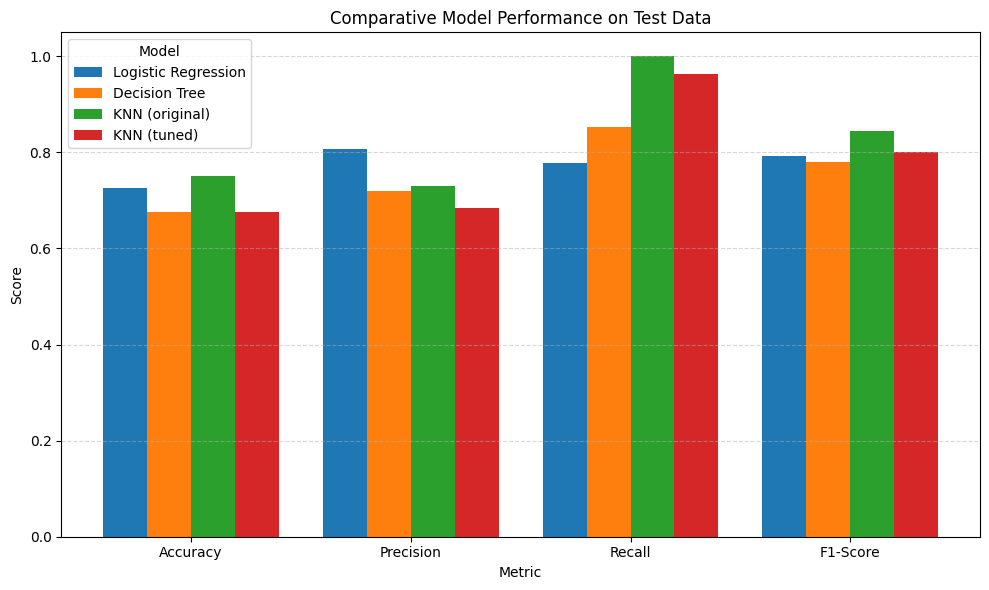

                     Accuracy  Precision  Recall  F1-Score
Logistic Regression     0.725     0.8077  0.7778    0.7925
Decision Tree           0.675     0.7188  0.8519    0.7797
KNN (original)          0.750     0.7297  1.0000    0.8438
KNN (tuned)             0.675     0.6842  0.9630    0.8000


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

results = {
    "Logistic Regression": {"Accuracy": 0.7250, "Precision": 0.8077, "Recall": 0.7778, "F1-Score": 0.7925},
    "Decision Tree": {"Accuracy": 0.6750, "Precision": 0.7188, "Recall": 0.8519, "F1-Score": 0.7797},
    "KNN (original)": {"Accuracy": 0.7500, "Precision": 0.7297, "Recall": 1.0000, "F1-Score": 0.8438},
    "KNN (tuned)": {"Accuracy": 0.6750, "Precision": 0.6842, "Recall": 0.9630, "F1-Score": 0.8000},
}

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
models = list(results.keys())

x = np.arange(len(metrics))
width = 0.2

fig, ax = plt.subplots(figsize=(10, 6))
for i, model in enumerate(models):
    values = [results[model][m] for m in metrics]
    ax.bar(x + i * width, values, width, label=model)

ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.set_title("Comparative Model Performance on Test Data")
ax.set_xticks(x + width * (len(models) - 1) / 2)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.05)
ax.legend(title="Model")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("model_comparison_chart.png", dpi=150)
plt.show()

import pandas as pd
summary_df = pd.DataFrame(results).T.round(4)
print(summary_df)
summary_df.to_csv("model_comparison_table.csv")